# Adaptive Legal RAG: история решений и результаты

**Состояние на 11 ноября 2026 года.** Это исследовательский ноутбук о том, как мы
сравнили способы поиска, выбрали основу пайплайна и проверяли последующие изменения.
Он собран из сохранённых локальных отчётов, без новых запросов к API. Графики уже
встроены и видны без запуска ячеек. Код графиков использует встроенные агрегаты,
поэтому его можно повторно запустить без базы знаний и доступа к API.

**Главный вывод:** выбран наш лексический поиск без векторов, дополненный адресными
связями и адаптивным поиском при нехватке оснований. Выбор опирался на результаты
старого сравнительного снимка и простоту эксплуатации; нынешнюю точность ответов
после удаления частных правил нельзя приравнивать к историческим 51/54. Новый тест
ретривера на 25 вопросах нашел два воспроизводимых пропуска, затем общий механизм
сопоставления склоненных имен был исправлен.

Файлы для сверки в репозитории: [описание пайплайна](../docs/PIPELINE.md)
и [новые 25 вопросов](../experiments/new25_retrieval_cases.json).
Агрегаты для графиков встроены в ячейки. Полные трассы API и база знаний
остаются локальными и в репозиторий не входят.


## 1. Как читать числа

| Обозначение | Что измеряет | Чего не измеряет |
| --- | --- | --- |
| `All@K` | Все размеченные фрагменты вопроса вошли в первые K найденных | Правильность ответа модели |
| `Hit@K` | Хотя бы один нужный фрагмент вошёл в первые K | Полноту составного ответа |
| «Полный верный» | Ответ по рубрике верен и полон | Корректность каждой ссылки |
| «Строгий зачёт» | Верный, полный ответ с подтверждающими ссылками | Независимую юридическую экспертизу |
| Начальное покрытие | Все основания попали в контекст до дополнительного поиска | Итог после адаптивных проходов |
| `answered` | Пайплайн выдал ответ | То, что ответ действительно верен |

В исходном сравнении — **54 вопроса**: 17 демонстрационных с основаниями,
12 дополнительных и 24 новых, зафиксированных до результатов. Ещё один
демонстрационный вопрос не имеет ответа в базе; поэтому метрики извлечения
считаются по **53**, а готовые ответы — по **54**. Демонстрационные вопросы
использовались при доработке ранжирования. Подмножество 24 новых информативнее,
но одного небольшого прогона недостаточно для уверенного превосходства.


## 2. Хронология: что сделали и зачем

| Этап | Изменение | Проверка или причина перехода |
| --- | --- | --- |
| Первое ядро | ZIP-база → фрагменты с ID → поиск по словам → один вызов генератора | На 17 демонстрационных вопросах исходный поиск собрал все основания в первых 12 только в 9 случаях |
| Улучшение словесного поиска | Вес текста пункта отдельно от заголовка, русские формы через триграммы, точные номера договоров и имена контрагентов, корректная обработка диалога | All@12 вырос до 17/17 на знакомом наборе; на 12 дополнительных — 11/12 |
| Сравнение способов поиска | BM25, BM25 с формами, BGE-M3, обычный гибрид, локальный граф, наш поиск, наш поиск + BGE | 54 фиксированных вопроса, единые фрагменты; BGE-M3 запущена на Tesla T4 в Colab |
| Сравнение готовых ответов | 7 методов × 54 вопроса = 378 ответов DeepSeek по одинаковому промпту | Наш вариант дал 51/54 строгих зачётов, обычный гибрид 48/54; результат исторический и не независимый |
| Выбор основы | Наш поиск без векторов по умолчанию | Сходное извлечение при K=12, меньше зависимостей и ниже время поиска; победа на других базах не доказана |
| Адаптивный IRAC-пайплайн | Планирование, поиск при пробеле, граф фактов, проверка, исправление, строгий IRAC, телеметрия и граница доверия | Исторический v7.1: 51/54 строгих зачётов против 49/54 однопроходного baseline; расход токенов существенно выше |
| Удаление частных правил | Убраны привязки к названиям/годам файлов, тематические подстановки и предположение о пункте 1.1 | Требование универсальности для аналогично устроенной базы другой компании; начальное покрытие упало до 51/53 |
| Исправление графа ссылок | Явное название + дата редакции + номер пункта; приоритет целевого пункта | N04 вернулся в начальный контекст, покрытие 52/53, один API-ответ N04 стал полным |
| Новый набор | 25 новых вопросов с эталонами, зафиксированными до поиска | 23/25 в начальном контексте; два пропуска из-за склоненных названий компаний |
| Общая нормализация имен | Сопоставление форм названий компаний в точном бонусе поиска | 25/25 на том же наборе; 52/53 на старом; 60 локальных тестов |

Эта таблица показывает последовательность, а не единый эксперимент: код,
контекст, промпты и объём работы менялись между этапами.


## 3. Что именно сравнивали

| Метод | Механизм | Требует GPU/векторного сервиса в использованной реализации? |
| --- | --- | --- |
| BM25 точный | Совпадение слов и статистика редкости | Нет |
| BM25 + формы | BM25 с русским стеммингом | Нет |
| BGE-M3 | Вектор запроса и фрагментов, близость в пространстве эмбеддингов | Да, в проведённом сравнении T4 |
| Обычный гибрид | BM25 + BGE-M3, объединение списков | Да |
| Гибрид + локальный граф | Обычный гибрид и один переход по немногим явным связям документов | Да |
| Наш без векторов | Слова, формы, триграммы, точные договоры/контрагенты, ограниченные явные связи | Нет |
| Наш + BGE-M3 | Наш лексический список объединён с плотным поиском | Да |

Использованы **21 документ и 312 фрагментов**, единое разбиение и обработка
диалогов. BGE-M3: `BAAI/bge-m3`, revision
`5617a9f61b028005a4858fdac845db406aefb181`, CLS pooling, L2,
FP16 на Tesla T4. Модель и документы индексировались локально в Colab;
сетевой API эмбеддингов в замеры поиска не входит. Реранкер **не запускался**:
проверенный шлюз ответил 404 на `/rerank`. Полноценный GraphRAG не проверялся:
`Гибрид + локальный граф` — три явные связи и один переход, причём добавление
связанных фрагментов в старой реализации не меняло первые 16 позиций.

Локальные исходные отчеты: `data/comparison/colab/results/comparison.json`
и `data/comparison/budget_comparison.json`. Агрегаты приведены в таблице
и встроены в код графика.


## 4. Качество извлечения

Для вывода о выборе метода особенно важны 24 новых вопроса. `All@K` требует
**всех** размеченных фрагментов; при составном вопросе один правильный фрагмент
не засчитывается как полный поиск.

| Метод | Все @5 | Все @12 | Все @16 | Все @12 на 53 | Все при 2048 токенах | Поиск, мс |
| --- | --- | --- | --- | --- | --- | --- |
| BM25 точный | 13/24 | 16/24 | 19/24 | 34/53 | 16/24 | 1.5 |
| BM25 + формы | 19/24 | 22/24 | 22/24 | 47/53 | 22/24 | 2.0 |
| BGE-M3 | 21/24 | 21/24 | 24/24 | 48/53 | 23/24 | 13.9 |
| Обычный гибрид | 21/24 | 23/24 | 23/24 | 50/53 | 23/24 | 15.9 |
| Гибрид + граф | 21/24 | 23/24 | 23/24 | 50/53 | 23/24 | 16.0 |
| Наш без векторов | 14/24 | 23/24 | 23/24 | 51/53 | 19/24 | 7.8 |
| Наш + BGE-M3 | 22/24 | 23/24 | 23/24 | 50/53 | 23/24 | 41.5 |

Столбец 2048 токенов пересчитан при **не более 16 фрагментах**. Его нельзя
приравнивать к `All@12`: одно ограничение задаёт число фрагментов, другое —
объём контекста. Здесь наш поиск уступил dense/гибриду: 19/24 против 23/24.
У BGE-M3 есть выигрыш на первых пяти: 21/24 против 14/24 у нашего поиска.
На `@12` наш и обычный гибрид одинаковы — 23/24, но пропускают разные вопросы.


In [ ]:
import matplotlib.pyplot as plt
plot_data = {'comparison': {'summaries': {'bm25': {'fresh_frozen': {'hit@5': 0.875, 'all@5': 0.5416666666666666, 'all@12': 0.6666666666666666, 'all@16': 0.7916666666666666, 'recall@12': 0.7916666666666666, 'mrr': 0.7299202746741155, 'all@2048tokens': 0.6666666666666666, 'context_tokens@12': 3167.1666666666665, 'latency_ms': 1.4941712499971043, 'n': 24}}, 'bm25_ru': {'fresh_frozen': {'hit@5': 0.9583333333333334, 'all@5': 0.7916666666666666, 'all@12': 0.9166666666666666, 'all@16': 0.9166666666666666, 'recall@12': 0.9375, 'mrr': 0.9120370370370369, 'all@2048tokens': 0.9583333333333334, 'context_tokens@12': 3072.8333333333335, 'latency_ms': 1.9542711250342866, 'n': 24}}, 'dense': {'fresh_frozen': {'hit@5': 1.0, 'all@5': 0.875, 'all@12': 0.875, 'all@16': 1.0, 'recall@12': 0.9375, 'mrr': 0.8576388888888888, 'all@2048tokens': 0.9583333333333334, 'context_tokens@12': 2678.75, 'latency_ms': 13.882233749977027, 'n': 24}}, 'hybrid': {'fresh_frozen': {'hit@5': 0.9583333333333334, 'all@5': 0.875, 'all@12': 0.9583333333333334, 'all@16': 0.9583333333333334, 'recall@12': 0.9791666666666666, 'mrr': 0.9017857142857143, 'all@2048tokens': 1.0, 'context_tokens@12': 2917.5, 'latency_ms': 15.921850583348865, 'n': 24}}, 'graph_local': {'fresh_frozen': {'hit@5': 0.9583333333333334, 'all@5': 0.875, 'all@12': 0.9583333333333334, 'all@16': 0.9583333333333334, 'recall@12': 0.9791666666666666, 'mrr': 0.9004629629629629, 'all@2048tokens': 0.9583333333333334, 'context_tokens@12': 2902.5, 'latency_ms': 15.965104791680082, 'n': 24}}, 'ours_current': {'fresh_frozen': {'hit@5': 0.875, 'all@5': 0.5833333333333334, 'all@12': 0.9583333333333334, 'all@16': 0.9583333333333334, 'recall@12': 0.9791666666666666, 'mrr': 0.737202380952381, 'all@2048tokens': 0.7916666666666666, 'context_tokens@12': 3137.9583333333335, 'latency_ms': 7.826116041674898, 'n': 24}}, 'ours_hybrid': {'fresh_frozen': {'hit@5': 1.0, 'all@5': 0.9166666666666666, 'all@12': 0.9583333333333334, 'all@16': 0.9583333333333334, 'recall@12': 0.9791666666666666, 'mrr': 0.8715277777777777, 'all@2048tokens': 0.9583333333333334, 'context_tokens@12': 3012.875, 'latency_ms': 41.51927679167026, 'n': 24}}}}, 'functional': {'methods': {'bm25': {'all': {'strict_pass': 38}, 'fresh24': {'strict_pass': 17}}, 'bm25_ru': {'all': {'strict_pass': 47}, 'fresh24': {'strict_pass': 20}}, 'dense': {'all': {'strict_pass': 42}, 'fresh24': {'strict_pass': 16}}, 'hybrid': {'all': {'strict_pass': 48}, 'fresh24': {'strict_pass': 21}}, 'graph_local': {'all': {'strict_pass': 48}, 'fresh24': {'strict_pass': 20}}, 'ours_current': {'all': {'strict_pass': 51}, 'fresh24': {'strict_pass': 22}}, 'ours_hybrid': {'all': {'strict_pass': 46}, 'fresh24': {'strict_pass': 17}}}}, 'timing': {'methods': [{'method': 'bm25', 'mean_total_tokens': 3447.0925925925926}, {'method': 'bm25_ru', 'mean_total_tokens': 3267.5185185185187}, {'method': 'dense', 'mean_total_tokens': 2811.240740740741}, {'method': 'hybrid', 'mean_total_tokens': 2983.8888888888887}, {'method': 'graph_local', 'mean_total_tokens': 3029.203703703704}, {'method': 'ours_current', 'mean_total_tokens': 3477.703703703704}, {'method': 'ours_hybrid', 'mean_total_tokens': 3155.3703703703704}]}, 'adaptive': {'search_total_mean_ms': 435.6487037037037, 'stage_mean_ms': {'context_pack': 1925.5396296296296, 'evidence_plan': 16171.42925925926, 'generation': 15100.675555555556, 'reference_and_neighbors': 339.1822222222222, 'repair': 2620.6044444444447, 'retrieval': 96.46666666666667, 'verification': 22760.841481481482}}}
comparison = plot_data['comparison']
functional = plot_data['functional']
timing = plot_data['timing']
adaptive = plot_data['adaptive']
methods = [('bm25', 'BM25'), ('bm25_ru', 'BM25 + формы'), ('dense', 'BGE-M3'), ('hybrid', 'Гибрид'), ('graph_local', 'Гибрид + граф'), ('ours_current', 'Наш'), ('ours_hybrid', 'Наш + BGE')]
plt.rcParams['font.family'] = 'DejaVu Sans'


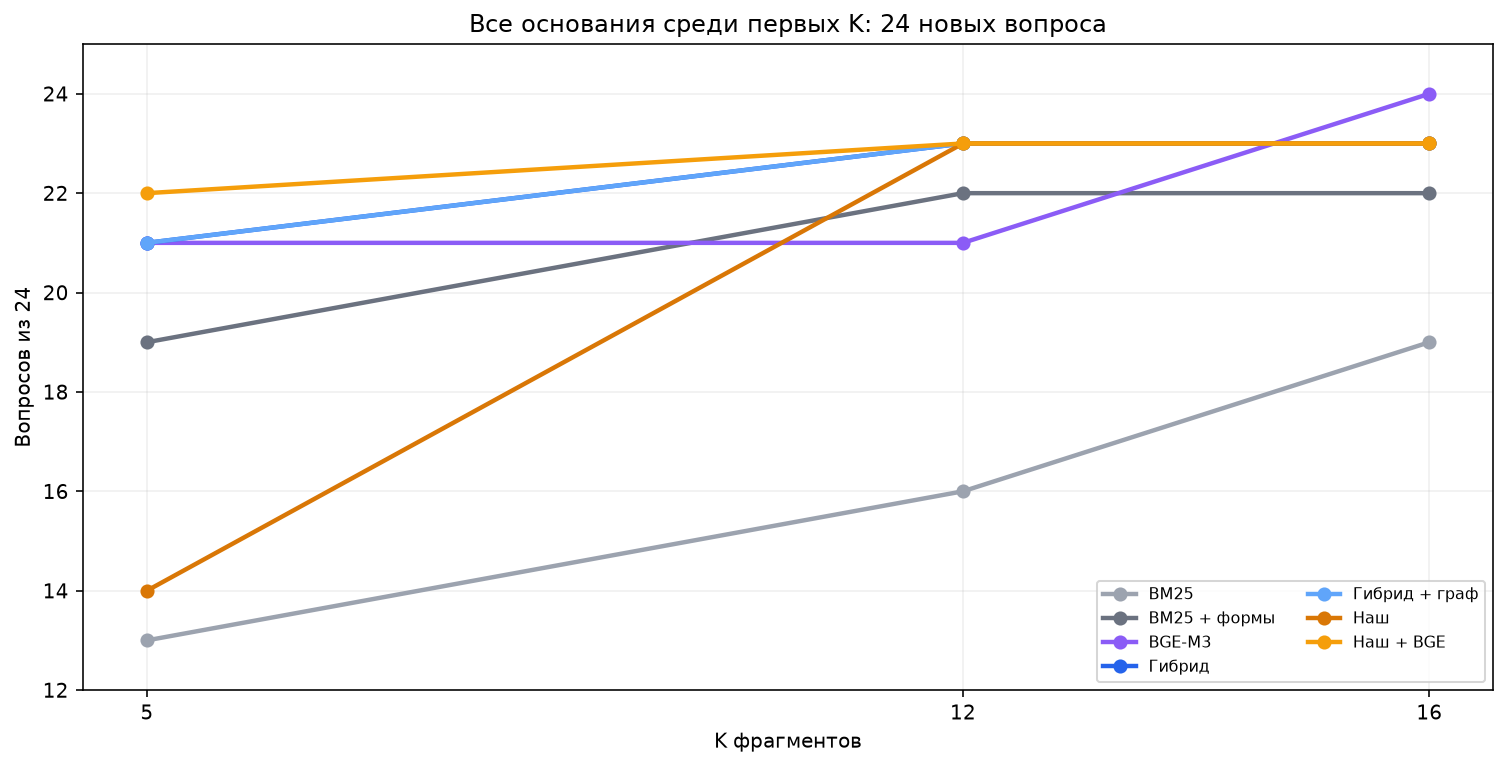

In [ ]:
fig, ax = plt.subplots(figsize=(10.5, 5.4))
colors = ['#9ca3af', '#6b7280', '#8b5cf6', '#2563eb', '#60a5fa', '#d97706', '#f59e0b']
for (key, name), color in zip(methods, colors):
    summary = comparison['summaries'][key]['fresh_frozen']
    y = [summary[f'all@{k}'] * 24 for k in (5, 12, 16)]
    ax.plot((5, 12, 16), y, marker='o', linewidth=2.2, label=name, color=color)
ax.set(title='Все основания среди первых K: 24 новых вопроса', xlabel='K фрагментов',
       ylabel='Вопросов из 24', xticks=(5, 12, 16), ylim=(12, 25))
ax.grid(alpha=.2)
ax.legend(ncol=2, loc='lower right', fontsize=8)
fig.tight_layout()
plt.show()


**Как читать график.** Близость кривых при K=12 не означает одинаковые ответы.
Вопрос N04 наш старый поиск пропускал, а обычный гибрид находил; вопрос N23
наоборот лучше обслуживался нашим вариантом. Порядок и объём найденного
контекста влияют на модель. Точки на графике — конкретный исторический снимок,
не текущая версия после очистки правил и исправления графа.


## 5. Качество готовых ответов при одном и том же генераторе

Сохранённые выдачи семи методов передавались `deepseek-v4.1-flash` с одинаковым
системным промптом, первыми 12 фрагментами, `temperature=0` и лимитом ответа.
Получено **378 ответов** (54 × 7). Оценка использовала рубрики по каждому
вопросу, скрытые названия методов и ручную сверку спорных случаев агентом.

| Метод | Полный верный | Строгий зачёт | Строгий на 24 новых | API, с/вопрос | Токенов/вопрос |
| --- | --- | --- | --- | --- | --- |
| BM25 точный | 42/54 | 38/54 | 17/24 | 8.94 | 3447 |
| BM25 + формы | 51/54 | 47/54 | 20/24 | 9.23 | 3268 |
| BGE-M3 | 49/54 | 42/54 | 16/24 | 8.88 | 2811 |
| Обычный гибрид | 52/54 | 48/54 | 21/24 | 10.35 | 2984 |
| Гибрид + граф | 52/54 | 48/54 | 20/24 | 8.87 | 3029 |
| Наш без векторов | 53/54 | 51/54 | 22/24 | 9.29 | 3478 |
| Наш + BGE-M3 | 50/54 | 46/54 | 17/24 | 9.15 | 3155 |

`API, с/вопрос` — время генерации ответа; к нему не следует прибавлять поиск
как будто это единый таймер всех этапов. Разница 51/54 против 48/54 и
22/24 против 21/24 невелика. Судья — та же модель, а ручная сверка агентом не
заменяет независимого юридического эксперта и многократных прогонов.

Локальные исходные отчеты: `data/functional_test/summary.json`,
`data/functional_test/timing.json`, `data/functional_test/manual_review.json`.


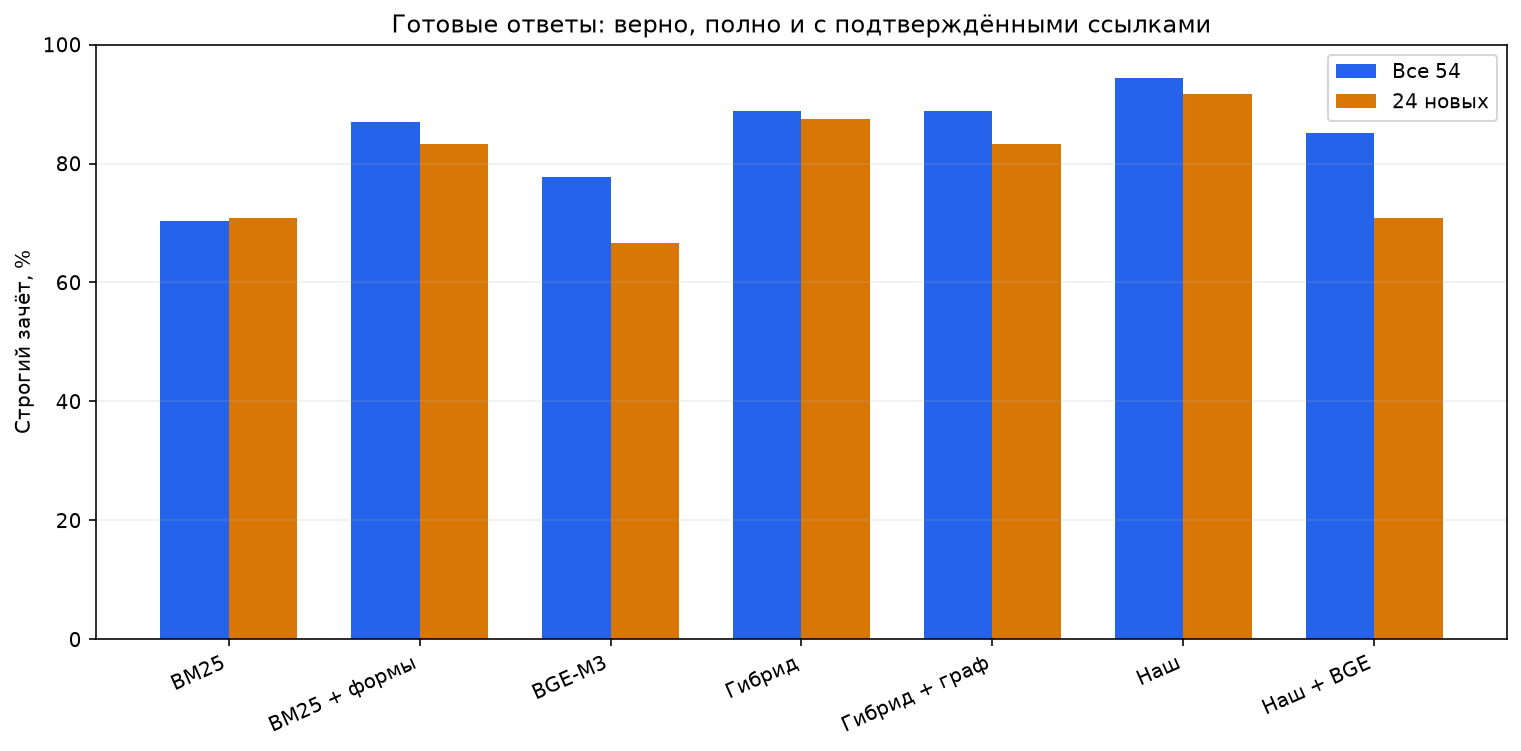

In [ ]:
fig, ax = plt.subplots(figsize=(10.6, 5.3))
names = [name for _, name in methods]
strict54 = [functional['methods'][key]['all']['strict_pass'] / 54 * 100 for key, _ in methods]
strict24 = [functional['methods'][key]['fresh24']['strict_pass'] / 24 * 100 for key, _ in methods]
positions = list(range(len(methods)))
ax.bar([x - .18 for x in positions], strict54, .36, label='Все 54', color='#2563eb')
ax.bar([x + .18 for x in positions], strict24, .36, label='24 новых', color='#d97706')
ax.set_xticks(positions, names, rotation=24, ha='right')
ax.set(ylabel='Строгий зачёт, %', title='Готовые ответы: верно, полно и с подтверждёнными ссылками', ylim=(0, 100))
ax.legend()
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
plt.show()


### Почему улучшение поиска не гарантировало улучшение ответа

| Наблюдение | Что произошло | Вывод для разработки |
| --- | --- | --- |
| N23 | Наш вариант нашёл состав цены мебели и отдельно коммунальные платежи по аренде; пять других потеряли один из пунктов | Для составного вопроса важна полнота двух документов |
| N04 | Старые наши варианты потеряли пункт 5.4 регламента, хотя нашли письмо о новой проверке | Граф явных ссылок полезен именно для адресного пункта |
| N01/N02 | При наличии двух редакций модель иногда смешивала адреса; даже `temperature=0` не устранил нестабильность | Надо проверять границу даты и согласованность вывода после поиска |
| N13/N24 | Модель добавила отсутствующий в фрагменте срок или спутала перечни с согласием и без | Наличие нужного текста не заменяет проверку утверждений |
| Наш + BGE-M3 | All@5 повысился до 22/24, но строгий ответ снизился до 46/54 | Новые кандидаты и порядок контекста могут ухудшить применение нормы; причинность одним прогоном не доказана |

Отсюда возникло разделение двух задач: **ретривер обязан подать нужные основания**,
а **генератор и проверяющий обязаны применить их без подмены условий**.


## 6. Почему выбрали наш поиск без векторов

Выбор был сделан пользователем после сравнения качества и затрат. В историческом
срезе наш метод и обычный гибрид оба получили **23/24 All@12** на новых
вопросах. Наш метод дал **51/54 строгих зачётов** против **48/54**, включая
**22/24** против **21/24** на новых. Время самого поиска было **7,8 мс**
против **15,9 мс** в локальном Colab-стенде. Он не требует GPU, весов BGE или
сервиса эмбеддингов в рабочем запуске. Обычный гибрид при равном бюджете
2048 токенов был лучше: **23/24 против 19/24**. Это важное ограничение выбора.

Преимущество по качеству не доказано статистически: выборка мала, часть вопросов
использовалась при разработке, оценка модели не независима. Поиск занимает
миллисекунды, генерация — секунды, поэтому уменьшение времени поиска само по
себе почти не меняет ожидание полного ответа. Денежную цену мы не считали:
нет тарифа шлюза и сведений о биллинге кеша.


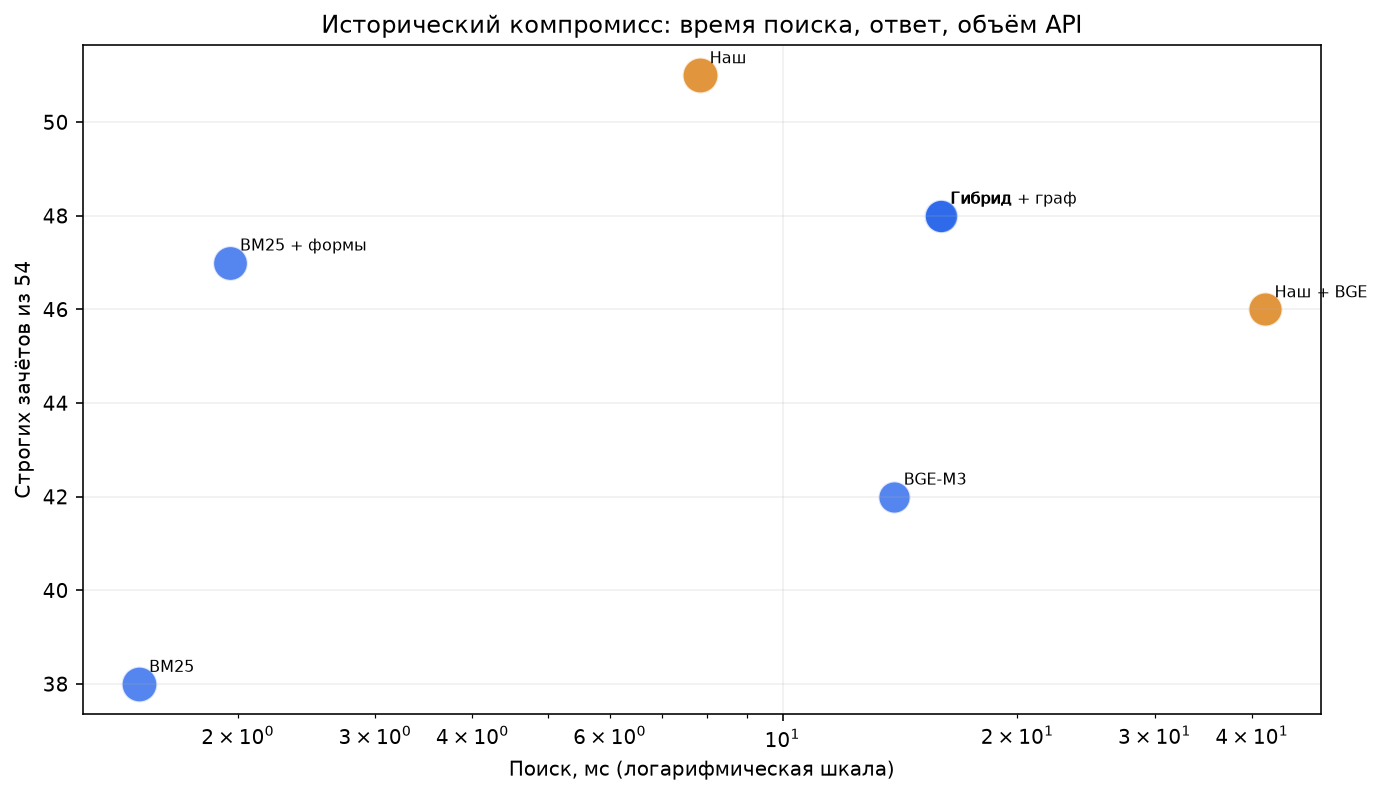

In [ ]:
fig, ax = plt.subplots(figsize=(9.7, 5.6))
for key, name in methods:
    search_ms = comparison['summaries'][key]['fresh_frozen']['latency_ms']
    strict = functional['methods'][key]['all']['strict_pass']
    tokens = next(item['mean_total_tokens'] for item in timing['methods'] if item['method'] == key)
    color = '#d97706' if key.startswith('ours') else '#2563eb'
    ax.scatter(search_ms, strict, s=tokens/11, alpha=.78, color=color, edgecolors='white')
    ax.annotate(name, (search_ms, strict), xytext=(5, 6), textcoords='offset points', fontsize=8)
ax.set_xscale('log')
ax.set(xlabel='Поиск, мс (логарифмическая шкала)', ylabel='Строгих зачётов из 54',
       title='Исторический компромисс: время поиска, ответ, объём API')
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()


Размер кружка на графике пропорционален среднему числу токенов одного ответа.
Он показывает **объём**, а не денежную цену. Токены разных методов связаны
с объёмом переданного контекста; сравнение основано на одном наборе запросов.


## 7. Что добавили поверх выбранного ретривера

```text
ZIP с документами → безопасное чтение и разбиение → лексический поиск
→ ограниченные явные связи и соседние пункты → контекст с ID источников
→ план подвопросов и извлечение фактов → при пробеле дополнительный поиск
→ генерация утверждений → отдельная проверка → при ошибке исправление
→ статический вывод I / R / A / C и телеметрия
```

| Компонент | Реализация и назначение | Ограничение |
| --- | --- | --- |
| Чтение базы | TXT/MD/DOCX из ZIP, пределы размера и числа файлов, ID/смещения фрагментов | Плохое разбиение может разорвать норму |
| Начальный поиск | Слова, формы, триграммы, номер договора, контрагент | Склонённые имена компаний пока дают пропуски |
| Поисковый граф | Только явные однозначные ссылки документов и пунктов | Не полноценный семантический GraphRAG; связь не доказывает приоритет нормы |
| Адаптивный проход | Модель называет конкретный пробел, локальный поиск получает ограниченный запрос | Может стоить ещё одного прохода и вызова API |
| Граф фактов | Субъект, отношение, объект, условия, точная цитата и ID | Извлечение модели может ошибаться |
| HalluGraph-проверка | Сопоставление графов источника и ответа плюс смысловая проверка | Та же модель может ошибаться; буквальное несовпадение троек даёт ложные сигналы |
| Проверки кода | ID, числа, договоры, имена, часть дат и отрицаний | Не доказывают юридическую применимость всех условий |
| Безопасность | Граница инструкций/данных, фильтр подозрительных строк, ограниченный JSON | Не является гарантией против любой инъекции |
| IRAC | Рендерер формирует I, R, A, C и ссылки на источники | Формат сам по себе не делает вывод истинным |
| Телеметрия | Поиск, упаковка, API-вызовы, токены, время по этапам | Денежная стоимость без тарифа неизвестна |

**Два разных графа:** поисковый связывает документы и пункты, а HalluGraph
сопоставляет факты источников с утверждениями ответа. Улучшение одного не
означает исправление другого. Рабочие файлы:
[`legal_core.py`](../legal_core.py),
[`adaptive_pipeline.py`](../adaptive_pipeline.py),
[`hallugraph.py`](../hallugraph.py),
[`rag_safety.py`](../rag_safety.py),
[`rag_telemetry.py`](../rag_telemetry.py).


## 8. Что дал адаптивный пайплайн и сколько он стоил

| Метрика | Исторический результат |
| --- | ---: |
| Полный прогон v7 | 54/54, все ответы в строгом IRAC |
| v7.1, строгий зачёт после сверки | 51/54 |
| Сохранённый однопроходный baseline, повторно проверенный | 49/54 |
| Полные верные ответы без требования ссылок: адаптивный / baseline | 51/54 / 53/54 |
| Полный ответ v7, среднее / медиана / p95 | 59.06 / 52.10 / 107.38 с |
| Поиск со связанными проходами, среднее | 435.6 мс |
| API-вызовов за 54 вопроса | 183 |
| Токенов v7: вход / выход | 1,466,434 / 96,854 |
| Токенов v7 всего | 1,563,288 |
| Токенов однопроходного baseline всего | 187,796 |
| Отношение объёмов токенов | 8.32× |

Разница строгого зачёта — **два вопроса**, но по правильности и полноте без
ссылок baseline был выше. Планирование, проверка и возможное исправление
дали стоимость в токенах примерно **8,32×** против старого одного вызова.
Это отношение объёмов, **не** отношение денежной цены. Не проводился прямой
замер времени двух вариантов в одном текущем окружении.

Исторический v7 получил статусы: {'insufficient': 2, 'answered': 46, 'partial': 4, 'technical_error': 1, 'clarification': 1}. Статус `answered`
не является оценкой содержания. Исходный v7.1 — исправление ссылок в
рендерере без новых модельных ответов; нельзя считать его независимым прогоном.
Локальные артефакты: `data/adaptive/full54_v7.json`,
`data/adaptive/full54_v7_summary.json`,
`data/adaptive/full54_v7_1_quality.json`.


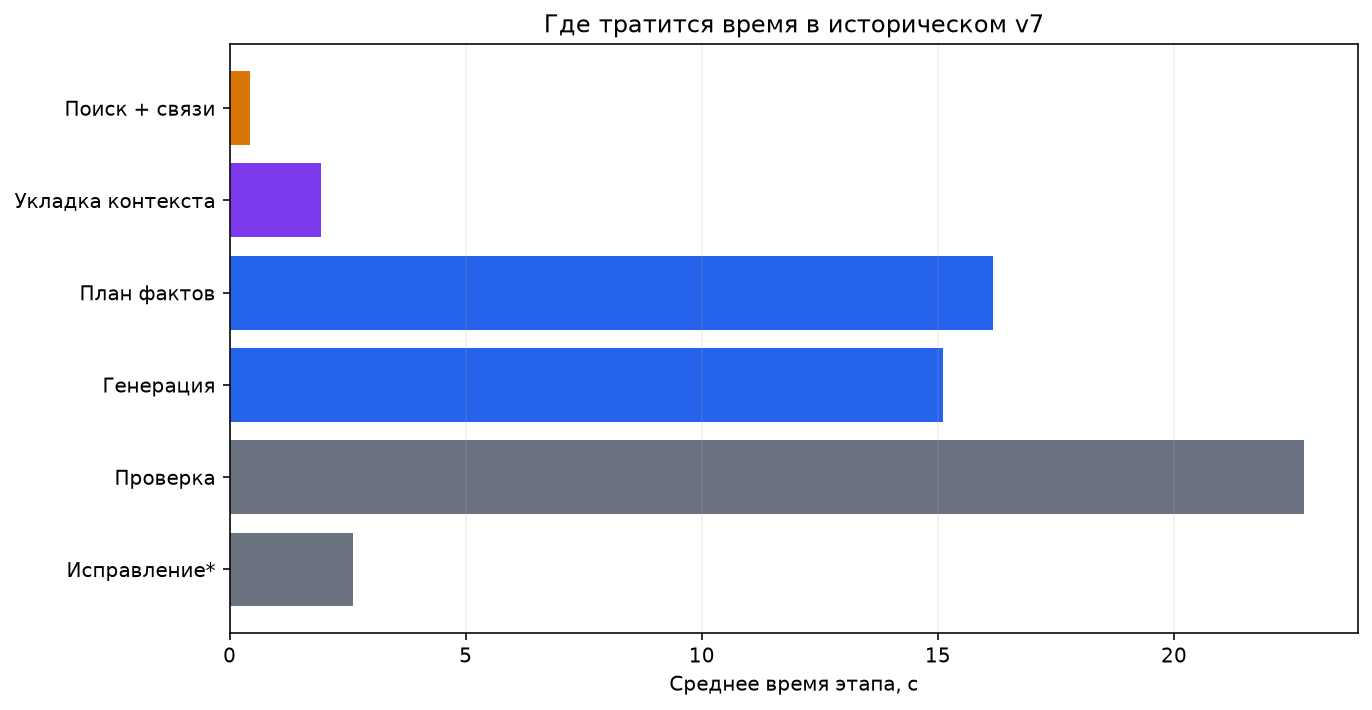

In [ ]:
fig, ax = plt.subplots(figsize=(9.6, 5.0))
names = ['Поиск + связи', 'Укладка контекста', 'План фактов', 'Генерация', 'Проверка', 'Исправление*']
values = [adaptive['search_total_mean_ms']/1000,
          adaptive['stage_mean_ms']['context_pack']/1000,
          adaptive['stage_mean_ms']['evidence_plan']/1000,
          adaptive['stage_mean_ms']['generation']/1000,
          adaptive['stage_mean_ms']['verification']/1000,
          adaptive['stage_mean_ms']['repair']/1000]
ax.barh(names[::-1], values[::-1], color=['#d97706','#7c3aed','#2563eb','#2563eb','#6b7280','#6b7280'][::-1])
ax.set(xlabel='Среднее время этапа, с', title='Где тратится время в историческом v7')
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
plt.show()


`*` Исправление вызывается не всегда; среднее по этому этапу следует читать
по определению сохранённой телеметрии. Показанные этапы нельзя складывать как
жёсткий таймер одного и того же запроса. Основная задержка связана с вызовами
модели, а не миллисекундами поиска.

Отдельный ограниченный тест безопасности: **24/24** заранее зафиксированных
сценария сохранили ожидаемые факты и IRAC; атакующий маркер и подложный ID
S9999 не попали в итог. Это 4 вопроса × 6 вариантов, не доказательство защиты
от всех атак. Реранкер по-прежнему отключён.


## 9. Что потом убрали и что изменилось

Пользователь справедливо потребовал, чтобы система работала на аналогично
устроенной базе другой компании. Поэтому удалены:

1. жёсткая связь по названию конкретного регламента и годам в именах файлов;
2. тематические подстановки поисковых запросов под знакомые вопросы;
3. правило «предмет договора находится в пункте 1.1» и автоматическая ссылка;
4. частные подсказки в промптах о конкретных расчётах/обязательствах;
5. предположение об общей дате действия для связанных норм.

Остались общие правила: извлечение номеров и имён из текста, явные ссылки,
дата редакции, проверяемые цитаты, IRAC и граница доверия. После очистки
начальное покрытие старых 53 вопросов снизилось с прежних 53/53 до **51/53**.
Это честная цена удаления подгонки: старые 53/53 больше нельзя считать
доказательством универсальности. Полный сквозной диагностический прогон на
очищенном коде дал статусы {'answered': 43, 'insufficient': 4, 'partial': 5, 'technical_error': 2}; эти статусы не равны точности,
а оценки того же модельного семейства не являются независимой экспертизой.

Затем исправили **общий механизм графовых ссылок**. Письмо ссылалось на
п. 5.4 регламента с кратким названием и датой редакции; заголовок документа
содержал ещё и имя организации, а слова стояли в другом падеже. Теперь связь
разрешается по нормализованному названию, дате и пункту без привязки к имени
файла. В N04 появились оба источника S0086 и S0122; начальное покрытие стало
**52/53**. Оставшийся вопрос 7 раньше находился во втором поиске и получил
правильный ответ. После графового изменения полный прогон 54 ответов не
повторялся.

Один новый API-прогон N04 дал полный IRAC-ответ с обоими источниками за
62.1 с и
26,045 входных +
2,379 выходных токенов.
Локально прошли **59 тестов**, включая вымышленные названия, годы и номера пунктов.
Поисковый граф остаётся небольшим; HalluGraph при N04 также выдал ложные
формальные замечания о связях, хотя смысловая проверка приняла ответ.


## 10. Проверка на 25 новых вопросах: найден конкретный сбой

Вопросы и нужные источники зафиксированы **до** запуска поиска. Проверка
локальная: нет LLM, дополнительных адаптивных запросов, векторов и реранкера.
Все размеченные основания вошли в начальный контекст у **23/25** вопросов.
Ниже — весь набор; «позиция» относится к исходному лексическому списку.

| ID | Новый вопрос | Все основания в контексте | Позиции нужных фрагментов |
| --- | --- | --- | --- |
| X01 | Аренда склада у «Северного Склада» сама закончится через год после подписания или срок в договоре устроен иначе? | **нет** | 50 |
| X02 | К какой дате нам должны были передать помещение в Химках при заключении аренды А-08/2024? | да | 3 |
| X03 | Можно ли использовать арендованное помещение «Северного Склада» как производственный цех вместо склада? Какое назначение записано? | да | 5 |
| X04 | Стороны аренды договорились изменить условия устно. Какая форма изменения предусмотрена самим договором А-08/2024? | да | 3 |
| X05 | Как отправить заявку на компьютеры «Альфа-Трейдингу» и какие сведения в неё вписать? | **нет** | 100 |
| X06 | Поставщик компьютеров прислал новый прайс. На какую дату берётся цена для заявки и за сколько дней нас должны предупредить о смене прайса? | да | 1, 2 |
| X07 | Если в заявке по ПТ-05/2023 указан адрес за пределами Москвы, что договор говорит о географии доставки? | да | 1 |
| X08 | Для компьютеров ПТ-05/2023 когда переходит собственность, а для мебели П-17/2024 какой документ определяет дату поставки? | да | 3, 4 |
| X09 | Сравните, от какого события считают срок доставки мебельной партии и компьютерной партии и сколько рабочих дней дано каждому поставщику. | да | 2, 3 |
| X10 | Мы отправили платёж за мебель, но деньги ещё не дошли до поставщика. В какой момент наше обязательство по оплате считается исполненным? | да | 1 |
| X11 | Поставщик мебели ссылается на форс-мажор. В какой срок он должен известить другую сторону, чтобы применялось договорное освобождение от ответственности? | да | 11 |
| X12 | По П-17/2024 претензию получили вчера. Сколько календарных дней есть на ответ и куда передают спор после обязательной претензионной стадии? | да | 1, 4 |
| X13 | За сколько календарных дней сторона должна письменно предупредить о своём отказе исполнять договор поставки мебели? | да | 1 |
| X14 | Если никто не сообщил о прекращении ПТ-05/2023 за 30 дней до конца срока, что произойдёт с договором на следующий календарный год? | да | 1 |
| X15 | В редакциях порядка согласования 2023 и 2025 годов сколько времени дают юридическому отделу и бухгалтеру, и появилось ли право продлить срок? | да | 1, 2 |
| X16 | В 2023 согласование делали на бумаге. Как оформляют его после вступления редакции 2025 года и нужен ли бумажный лист? | да | 2, 1 |
| X17 | Хотим согласовать аренду недвижимости по порядку 2025 года. Какой отдел участвует дополнительно? | да | 12 |
| X18 | Договор предусматривает обработку персональных данных. Кого нужно подключить к согласованию по регламенту с марта 2025 года? | да | 13 |
| X19 | Контрагент — наша аффилированная компания, сумма всего 100 тысяч рублей. Требуется ли согласование с финансовым директором по редакции 2025 года? | да | 1 |
| X20 | Сколько хранят оригинал договора в архиве юротдела после завершения договора или исполнения сторонами обязательств? | да | 1 |
| X21 | Можно ли спрятать согласие человека на обработку его данных внутри другого подписываемого документа или его оформляют отдельно? | да | 1 |
| X22 | Какие сведения о представителе нужны, если письменное согласие на обработку данных подписывает он, а не сам субъект? | да | 3 |
| X23 | Налоговое нарушение повторяет прежнее аналогичное. Что считается отягчающим обстоятельством и как меняется размер штрафа? | да | 1, 2 |
| X24 | Берём человека по трудовому договору ровно на два месяца. Можно ли установить ему испытание? | да | 2 |
| X25 | Для работников с вредными условиями труда подкласса 3.4 можно ли увеличить годовую сверхурочную работу до 240 часов по коллективному договору? | да | 1 |

**X01:** S0007 о неопределённом сроке аренды стоит на месте 50.
**X05:** S0062 о заявке по электронной почте и её содержимом — на месте 100.
В обоих вопросах компания названа в кавычках в косвенном падеже. Текущий поиск
удаляет строку в кавычках из обычных слов запроса, а бонус за сущность начисляет
только при точном совпадении с именем в документе. Замена только формы имени
на словарную подняла нужные пункты на позиции **3** и **5**. Это диагностический
контроль, не новая оценка исходных вопросов и не изменение продукта.

Реранкер не исправил бы эти два пропуска, поскольку нужные пункты не вошли
в его кандидатный набор. Локальный исходный отчет:
`data/adaptive/new25_retrieval_v1.json`.

**После фиксации исходного результата** в поиске добавили общую нормализацию
падежных форм имен компаний. Новый локальный прогон на тех же вопросах дал
**25/25**, X01 поднялся на 3-е место, X05 на 5-е. Старые вопросы сохранили
**52/53** в начальном контексте, все **60** локальных тестов прошли. Тесты
с вымышленными компаниями проверяют, что похожие названия не сливаются.
Это регрессионная проверка исправления на уже известном наборе, а не новая
независимая оценка. Для нее нужен отдельный заранее зафиксированный набор.
Локальный отчет после изменения: `data/adaptive/new25_retrieval_v2.json`.


## 11. Текущее состояние и открытые вопросы

| Что известно | Что ещё не подтверждено |
| --- | --- |
| Текущий поиск без векторов и реранкера; 52/53 на старых вопросах в начальном контексте | Полная точность 54 ответов после очистки, графового и именного исправлений |
| Исходный новый набор 23/25, после исправления 25/25 на тех же вопросах | Независимое качество на другом новом наборе и качество итоговых ответов на этих 25 |
| Один новый N04 ответил полностью после графового исправления | Что граф улучшит другие базы и другие формы ссылок |
| 60 локальных тестов прошли | Независимая юридическая оценка и многократные прогоны |
| BGE-M3 измерена на T4, реранкер не запускался | Цена шлюза и стойкий сервер эмбеддингов/реранкера |

После изменения нужен **новый** слепой набор, а старые 54 и эти 25
служат регрессией. Следом стоит измерить качество ответа отдельно от качества
извлечения и уменьшить дорогие вызовы планировщика/проверяющего там, где
проверка может быть дешевле. Этот репозиторий пока содержит только backend.

### Воспроизведение без API

```powershell
python -X utf8 -m unittest discover -s tests
python -X utf8 experiments/evaluate_frozen_retrieval.py --questions experiments/new25_retrieval_cases.json --output data/adaptive/new25_retrieval_recheck.json
```

Второй вызов требует **нового** имени выходного файла: оценщик не перезаписывает
сохраненный отчет. Графики в ноутбуке используют встроенные агрегаты и
перестраиваются без API или исходной базы. Исторические GPU/API-замеры
не пересчитываются. Ключи не сохранены.
